# 5. 생산량 (매출·판매 계획)

| 세부 기능 | 판매자 질문 예시 | 도구 |
| --- | --- | --- |
| 5-1 시기별 매출 증감 | "내 월별 매출 어때?" | `sales_trend`, `plot_sales_trend` |
| 5-2 카테고리 판매 순위 | "뭐가 잘 팔려?" | `category_ranking`, `plot_category_rank` |
| 5-3 카테고리별 매출 비중 파이 | "시장 전체에서 카테고리 비중?" | `category_ranking`, `plot_category_pie` |
| 5-4 가격·운송비·할부 점검 | "내 가격 비싼 편이야?" | `price_position` |
| 5-5 생산(판매) 계획 | "다음 달 카테고리별로 몇 개 준비해?" | `production_plan` |

**주의**: 데이터에 생산 정보는 없어서 "판매량 = 생산(준비)해야 할 양"으로 봐요. 매출은 상품가 합이고 운송비는 빼요.

**실행법 (Colab)**: GitHub 저장소(jc020230/BDA)에서 이 노트북을 Colab으로 열고 위에서부터 실행하면 돼요. 첫 셀이 저장소를 자동으로 내려받아서 `seller_tools.py`와 `preprocessing/` 폴더의 데이터를 찾아요. 노트북끼리는 서로 독립이라 아무거나 먼저 열어도 돼요.

**아래 "챗봇이 이렇게 말할 수 있어요"** 문장은 도구 결과 숫자로 자동으로 만든 예시예요. 실제 챗봇에서는 LLM이 이 결과를 받아 자연스럽게 말해요.

In [1]:
# 준비: 저장소 파일(seller_tools.py, 전처리 데이터)을 찾고, 없으면 GitHub에서 내려받기
import os, sys, json, zipfile, subprocess
IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/jc020230/BDA.git'
DATA_DIRS = ['olist_mart', 'preprocessing', '/content/drive/MyDrive/olist_mart']
has_data = lambda p: os.path.exists(f'{p}/orders_mart.parquet')

# Colab에서 GitHub 노트북만 열면 다른 파일이 없어서, 저장소를 통째로 내려받아 그 폴더로 이동
if not os.path.exists('seller_tools.py'):
    if not os.path.exists('BDA/seller_tools.py'):
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, 'BDA'], check=True)
    os.chdir('BDA')
MART_DIR = next((p for p in DATA_DIRS if has_data(p)), None)
if MART_DIR is None:   # 저장소에 데이터가 없으면 zip이나 드라이브에서 찾기
    z = next((p for p in ['olist_mart_v2_github.zip', 'olist_mart_v2.zip', 'olist_mart.zip'] if os.path.exists(p)), None)
    if z: zipfile.ZipFile(z).extractall('.'); MART_DIR = 'olist_mart'
    elif IN_COLAB:
        from google.colab import drive; drive.mount('/content/drive'); MART_DIR = next(p for p in DATA_DIRS if has_data(p))

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from seller_tools import SellerTools, TOOLS, setup_korean_font
setup_korean_font()
st = SellerTools(MART_DIR)
if st.evm_table is None:
    print('⚠️ 전처리 1판 결과예요. 2판을 쓰면 이벤트 배수 표와 도착 전 리뷰 기능까지 쓸 수 있어요.')

def show(result, limit=1500):
    """도구 결과(JSON)를 보기 좋게 출력"""
    text = json.dumps(result, ensure_ascii=False, indent=1)
    print(text if len(text) <= limit else text[:limit] + '\n... (생략)')

DEMO = '2eb70248'                  # 시계·선물, 별점 낮고 발송이 느린 판매자 (앞 8자리만 써도 됨)
BIG = st.ss.orders.idxmax()        # 주문이 가장 많은 판매자
print('도구', len(TOOLS), '개 준비 완료 | 작업 폴더:', os.getcwd(), '| 데이터:', MART_DIR)

도구 23 개 준비 완료 | 작업 폴더: /tmp/repo_asof | 데이터: preprocessing


## 5-1. 시기별 매출 증감 (내 가게 vs 시장)

  year_month  orders   revenue  revenue_mom  market_revenue_mom
0    2018-02       5   2609.54          NaN               -0.11
1    2018-03       9   5562.90        1.132                0.17
2    2018-04      26   3405.20       -0.388                0.01
3    2018-05      92  15866.69        3.660               -0.00
4    2018-06      11   2148.00       -0.865               -0.13
5    2018-07      59  13036.28        5.069                0.02


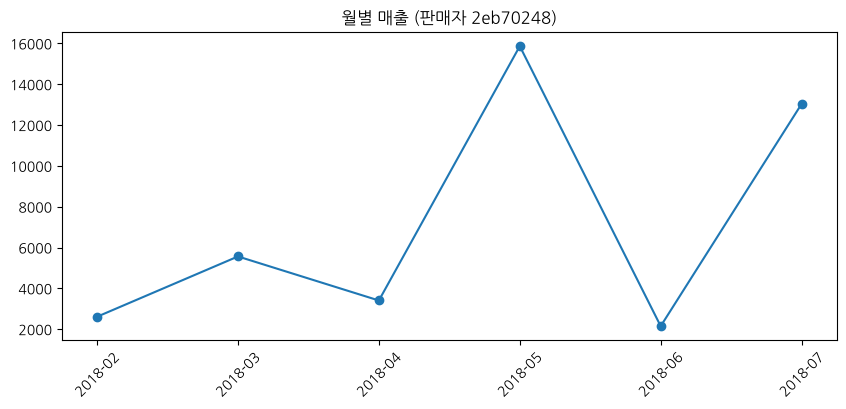

💬 가장 매출이 높았던 달은 2018-05예요. 마지막 달(2018-07) 매출은 13,036헤알로 전월 대비 +507%였고, 같은 달 시장 전체는 +2%였어요.


In [2]:
r = st.call('sales_trend', {'seller_id': DEMO})
m = pd.DataFrame(r['monthly']); print(m.round(3))
st.plot('plot_sales_trend', seller_id=DEMO); plt.show()
last = m.iloc[-1]
print('💬', f"가장 매출이 높았던 달은 {r['best_month']}예요. 마지막 달({last.year_month}) 매출은 {last.revenue:,.0f}헤알로 전월 대비 {last.revenue_mom:+.0%}였고, "
      f"같은 달 시장 전체는 {last.market_revenue_mom:+.0%}였어요.")

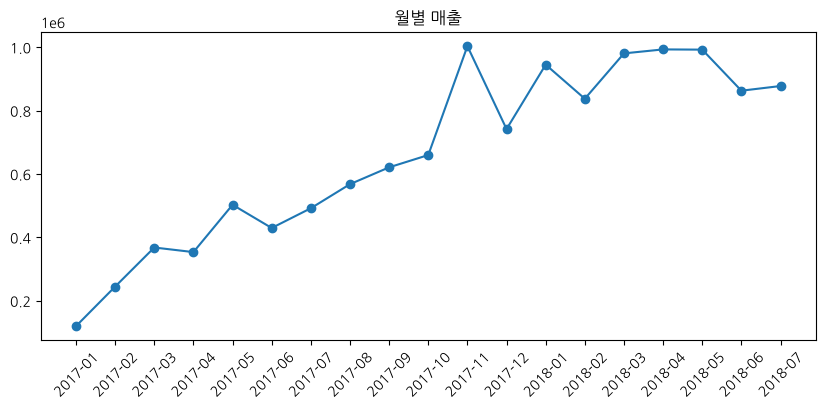

💬 시장 전체 매출이 가장 크게 뛴 달은 2017-02(+104%)예요.


In [3]:
r = st.call('sales_trend', {})
st.plot('plot_sales_trend'); plt.show()
m = pd.DataFrame(r['monthly']).set_index('year_month')
print('💬', f"시장 전체 매출이 가장 크게 뛴 달은 {m.revenue_mom.idxmax()}({m.revenue_mom.max():+.0%})예요.")

## 5-2. 카테고리 판매 순위

  category_ko     revenue  units  orders  share
0       건강·뷰티  1210184.75   9283    8481  0.092
1       시계·선물  1177147.73   5850    5491  0.089
2    침구·욕실·식탁  1014921.30  10862    9197  0.077
3      스포츠·레저   963063.34   8399    7495  0.073
4    컴퓨터 액세서리   892960.16   7617    6503  0.068
5     가구·인테리어   711238.33   8100    6268  0.054
6       쿨 아이템   615596.30   3734    3571  0.047
7        생활용품   607058.62   6667    5634  0.046
8       자동차용품   569057.17   4082    3755  0.043
9        정원용품   475688.27   4284    3468  0.036


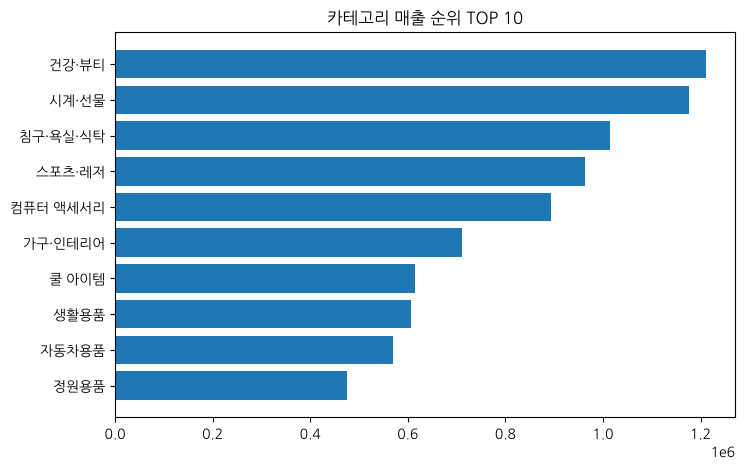

수량 기준 TOP 5: ['침구·욕실·식탁', '건강·뷰티', '스포츠·레저', '가구·인테리어', '컴퓨터 액세서리']


In [4]:
r = st.call('category_ranking', {'top': 10})
print(pd.DataFrame(r['ranking']).round(3))
st.plot('plot_category_rank'); plt.show()
r_u = st.call('category_ranking', {'by': 'units', 'top': 5})
print('수량 기준 TOP 5:', [x['category_ko'] for x in r_u['ranking']])

## 5-3. 카테고리별 매출 비중 파이 (시장 vs 내 가게)

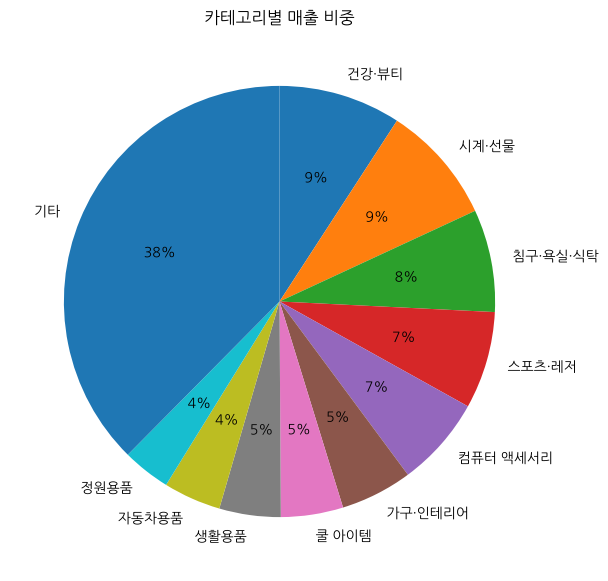

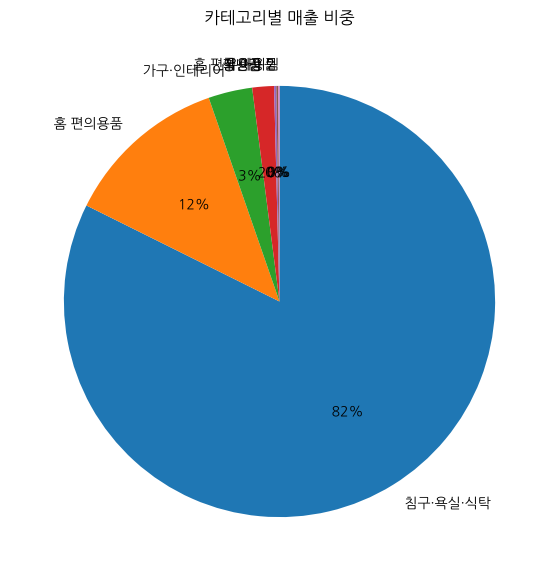

💬 시장 매출 비중 상위: 건강·뷰티 9%, 시계·선물 9%, 침구·욕실·식탁 8%, 나머지 38%는 기타예요.


In [5]:
st.plot('plot_category_pie'); plt.show()
st.plot('plot_category_pie', seller_id=BIG); plt.show()
pie = pd.DataFrame(st.call('category_ranking', {'top': 10})['pie'])
print('💬', '시장 매출 비중 상위: ' + ', '.join(f"{a} {b:.0%}" for a, b in zip(pie.category_ko[:3], pie.share[:3])) + f", 나머지 {pie.share.iloc[-1]:.0%}는 기타예요.")

## 5-4. 가격 위치·운송비·할부 점검

In [6]:
r = st.call('price_position', {'seller_id': DEMO})
print(pd.DataFrame(r['products'])[['category_ko', 'units', 'price', 'price_percentile_in_category', 'freight_ratio', 'market_installment_share_at_price']].round(2))
print('\n💬 ' + (' '.join(r['tips']) if r['tips'] else '가격과 운송비에서 특별히 걸리는 점은 없어요.'))

  category_ko  units   price  price_percentile_in_category  freight_ratio  \
0    컴퓨터 액세서리     68   79.90                          0.50           0.16   
1       시계·선물     57  155.97                          0.40           0.10   
2       시계·선물     30  124.90                          0.30           0.13   
3       시계·선물     10  173.90                          0.45           0.09   
4       시계·선물      5  494.00                          0.78           0.02   
5       시계·선물      4  539.00                          0.79           0.03   
6      게임기·게임      4  703.90                          0.98           0.03   
7       시계·선물      4  133.90                          0.32           0.11   
8         미분류      3  399.90                          0.95           0.05   
9        유아용품      2  607.95                          0.95           0.04   

   market_installment_share_at_price  
0                               0.64  
1                               0.80  
2                               0.8

## 5-5. 생산(판매) 계획
4번의 수요 예측을 카테고리별로 모아서, 다음 몇 주에 **몇 개를 준비하고 매출이 얼마일지** 보여줘요. 이벤트가 끼어 있으면 배수가 반영돼요.

       category_en category_ko  forecast_units  median_price  \
0   bed_bath_table    침구·욕실·식탁            56.4         89.90   
1     home_confort      홈 편의용품            11.2         89.90   
2             toys         장난감             1.6         58.80   
3  furniture_decor     가구·인테리어             0.8         82.90   
4             baby        유아용품             0.8         68.85   
5   home_comfort_2    홈 편의용품 2             1.2         12.90   

   forecast_revenue events_in_horizon confidence  backtest_mae_8w  \
0           5070.36                []         높음             3.76   
1           1006.88                []         높음             1.75   
2             94.08                []         보통             0.65   
3             66.32                []         낮음             0.40   
4             55.08                []         낮음             0.47   
5             15.48                []         보통             0.61   

   revenue_share  
0           0.80  
1           0.16  
2         

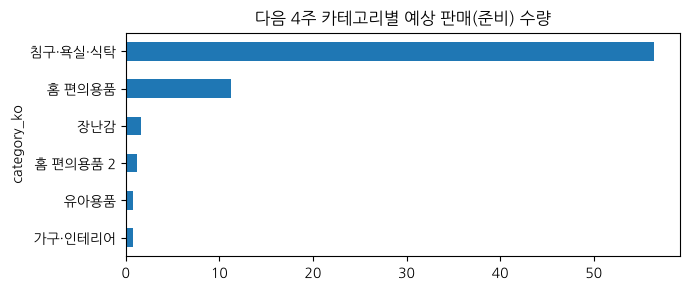

💬 다음 4주 동안 약 72개, 매출 약 6,308헤알이 예상돼요. 그중 80%가 '침구·욕실·식탁' 카테고리예요.


In [7]:
r = st.call('production_plan', {'seller_id': BIG, 'horizon_weeks': 4})
p = pd.DataFrame(r['plan']); print(p.round(2))
ax = p.set_index('category_ko').forecast_units.sort_values().plot(kind='barh', figsize=(7, 3), title='다음 4주 카테고리별 예상 판매(준비) 수량'); plt.tight_layout(); plt.show()
print('💬', f"다음 4주 동안 약 {r['total_units']:.0f}개, 매출 약 {r['total_revenue']:,.0f}헤알이 예상돼요. 그중 {p.revenue_share[0]:.0%}가 '{p.category_ko[0]}' 카테고리예요.")

In [8]:
# 블랙프라이데이가 끼어 있던 시점에서 계획을 세웠다면 (과거 시점 재현)
r = st.call('production_plan', {'seller_id': BIG, 'horizon_weeks': 4, 'as_of': '2017-11-06'})
pd.DataFrame(r['plan'])[['category_ko', 'forecast_units', 'forecast_revenue', 'events_in_horizon', 'confidence']].round(1)

,category_ko,forecast_units,forecast_revenue,events_in_horizon,confidence
0,침구·욕실·식탁,141.3,12702.9,[블랙프라이데이],높음
1,홈 편의용품,20.4,1834.0,[블랙프라이데이],높음
2,가구·인테리어,4.8,397.9,[블랙프라이데이],보통
3,장난감,4.9,288.1,[블랙프라이데이],보통
4,홈 편의용품 2,5.1,65.8,[블랙프라이데이],보통
